### Do the random walk

In [177]:
import math
import random
import numpy as np
import scipy.stats as stats

In [178]:
def random_walk(num_steps):
    '''Vectorized 2-dimensional random walk
    This generates num_steps random angles in the plane, and returns the final
    position of the particle, assuming a unitary step length.'''
    
    phi = np.random.uniform(0., 2. * np.pi, num_steps)

    # Calculate the displacemente along the two orthogonal axes at each step.
    dx = np.cos(phi)
    dy = np.sin(phi)

    # Sum all the displacements to get the final position.
    x = dx.sum()
    y = dy.sum()

    # Return the final position.
    return (x, y)

In [179]:
num_simulations = 100
num_steps = 100  
simulations = [random_walk(num_steps) for _ in range(num_simulations)]
x_coords, y_coords = zip(*simulations)

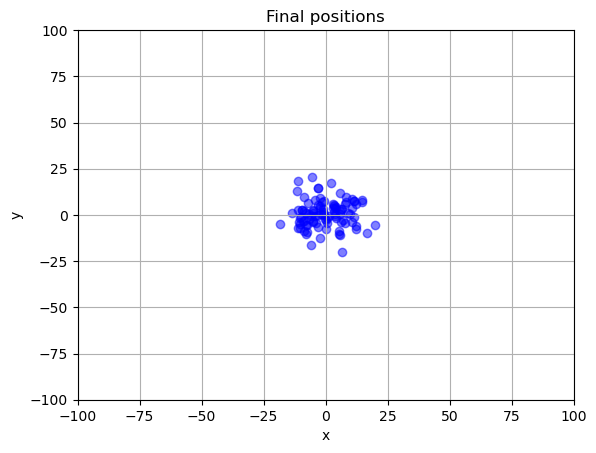

In [180]:
# Scatter plot

import matplotlib.pyplot as plt

plt.scatter(x_coords, y_coords, color='blue', alpha=0.5)

plt.xlabel('x')
plt.ylabel('y')
plt.axis([-100, 100, -100, 100]) 
plt.title('Final positions')
plt.grid()

plt.show()

note:  

the * in *simulations is used for unpacking  
means to pass simulations, a list of tuples, one tuple at a time  
so zip is applied to one tuple at a time  

In [181]:
distance = [math.sqrt(x**2+y**2) for x,y in zip(x_coords, y_coords)]
print(distance)

[11.418495544917459, 9.680866892990958, 4.208080483918971, 5.74885367399392, 7.000294786995521, 14.750686448053534, 11.377880740459004, 5.84189110769214, 21.200037051989185, 9.262430858108644, 9.9110499303009, 21.26387301254052, 4.239351035766852, 7.45005078042755, 6.313902288693369, 9.143352291577202, 13.860477279139383, 0.9824136026173236, 6.242966761061252, 9.79150242868126, 12.574051559529849, 12.761020835356723, 12.325114019350346, 9.94352615571404, 6.897839944407022, 2.9067972600435232, 5.233775684248841, 14.742100642371511, 11.489566520540302, 11.791231409304938, 7.620878693480427, 16.792518030895955, 7.634013359236508, 10.256067754695922, 9.166465869891072, 11.115220544013233, 5.34650022451236, 13.046401524124429, 9.522987744228338, 12.87202927758575, 1.4502571938710493, 4.512952884367567, 5.581459816295214, 2.2988271188315914, 13.718511235869688, 12.542799620567997, 7.297994599019681, 3.3036200343406734, 10.870400422591217, 13.201824133860606, 9.002882811158054, 6.132694107212

### Expected stuff: x,y

In [182]:
# split x,y in bins

num_bins = 100
bins_x = np.linspace(-30, 30, num_bins + 1)

In [183]:
# Find expected gaussian distribution of x and y  

expected_mean = 0  
expected_dev = math.sqrt(num_steps/2)  
expected_area = num_simulations


bin_width = bins_x[1] - bins_x[0]
bin_centers = (bins_x[:-1] + bins_x[1:]) / 2  
gaussian_pdf = stats.norm.pdf(bin_centers, expected_mean, expected_dev)
expected_occ_x = gaussian_pdf * num_simulations * bin_width   # after scaling
expected_occ_x = expected_occ_x.round()

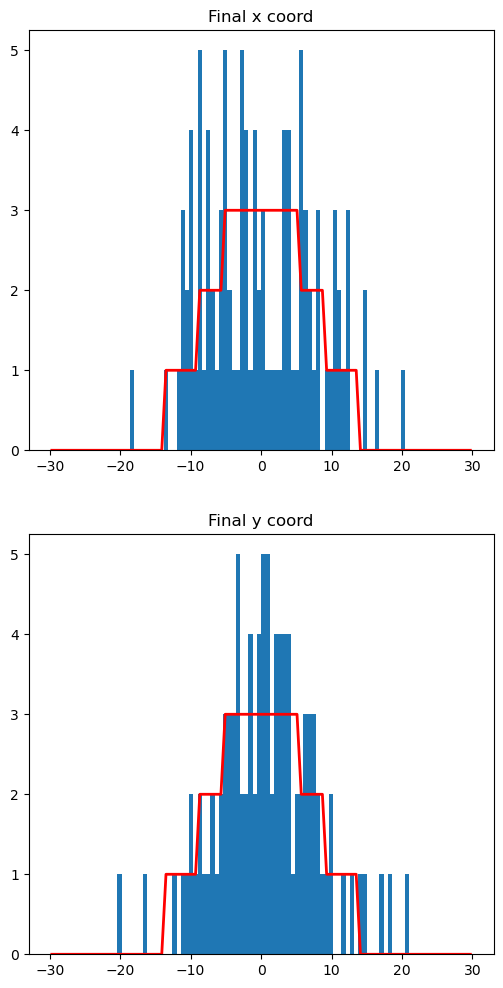

In [184]:
# Histogram

fig, ax = plt.subplots(2, figsize=(6,12))

occ_x, bins_x, _ = ax[0].hist(x_coords, bins=bins_x)
occ_y, bins_y, _ = ax[1].hist(y_coords, bins=bins_x)

# density=True normalizes the area to 1, don't do it or won't have nuber of occurrences

ax[0].set_title('Final x coord')
ax[1].set_title('Final y coord')

ax[0].plot(bin_centers, expected_occ_x, 'r-', linewidth=2, label="Expected Gaussian")
ax[1].plot(bin_centers, expected_occ_x, 'r-', linewidth=2, label="Expected Gaussian")


### Distance

In [185]:
# split d in bins

bins_d = np.linspace(0, 40, num_bins + 1)

In [186]:
# d follows a chi-squared distribution with DOF=2, bc it's sum of 2 gaussians, x and y  

def chi2_pdf(d,n): 
    return (2 * d / n) * np.exp(-d**2 / n)

In [187]:
# Find expected gaussian distribution of d

expected_area = num_simulations

bins_d = np.linspace(0, 40, num_bins + 1)
bin_width_d = bins_d[1] - bins_d[0]
bin_centers_d = (bins_d[:-1] + bins_d[1:]) / 2  
chi_pdf = chi2_pdf(bin_centers_d, num_steps)
expected_occ_d = chi_pdf * num_simulations * bin_width_d   # after scaling
expected_occ_d = expected_occ_d.round()


In [188]:
print(bin_centers_d)

[ 0.2  0.6  1.   1.4  1.8  2.2  2.6  3.   3.4  3.8  4.2  4.6  5.   5.4
  5.8  6.2  6.6  7.   7.4  7.8  8.2  8.6  9.   9.4  9.8 10.2 10.6 11.
 11.4 11.8 12.2 12.6 13.  13.4 13.8 14.2 14.6 15.  15.4 15.8 16.2 16.6
 17.  17.4 17.8 18.2 18.6 19.  19.4 19.8 20.2 20.6 21.  21.4 21.8 22.2
 22.6 23.  23.4 23.8 24.2 24.6 25.  25.4 25.8 26.2 26.6 27.  27.4 27.8
 28.2 28.6 29.  29.4 29.8 30.2 30.6 31.  31.4 31.8 32.2 32.6 33.  33.4
 33.8 34.2 34.6 35.  35.4 35.8 36.2 36.6 37.  37.4 37.8 38.2 38.6 39.
 39.4 39.8]


In [189]:
print(expected_occ_d)

[0. 0. 1. 1. 1. 2. 2. 2. 2. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3.
 3. 3. 3. 3. 2. 2. 2. 2. 2. 2. 2. 2. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]


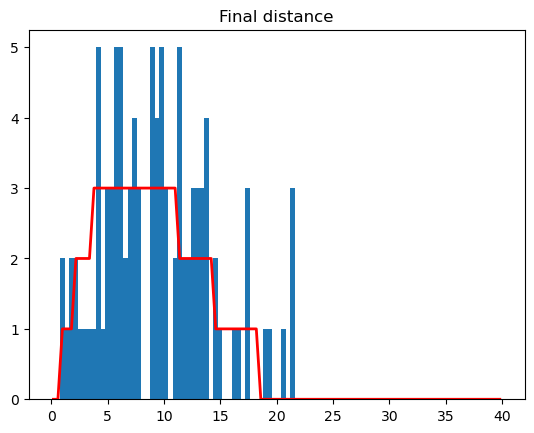

In [190]:
occ_d, _, _ = plt.hist(distance, bins=bins_d)
plt.title('Final distance')

plt.plot(bin_centers_d, expected_occ_d, 'r-', linewidth=2)

# density=True normalizes the area to 1, don't do it or won't have nuber of occurrences

### P-test

In [191]:
# X,Y

# Compute it
# note that expected occurrences are the same

chi_x = sum( (o-e)**2/e for o,e in zip(occ_x, expected_occ_x) if e != 0)
chi_y = sum( (o-e)**2/e for o,e in zip(occ_y, expected_occ_x) if e != 0)
print('Computed chi:', chi_x, chi_y)  

DOF_x = num_bins
print('Expected chi', DOF_x)


Computed chi: 59.66666666666667 21.500000000000007
Expected chi 100


In [192]:
chi_d = sum( (o-e)**2/e for o,e in zip(occ_d, expected_occ_d) if e != 0)
print('Computed chi:', chi_d)  

DOF_d = num_bins
print('Expected chi:', DOF_d)


Computed chi: 43.166666666666664
Expected chi: 100


In [193]:
# COmpute p-values

import scipy.stats

chi2 = scipy.stats.chi2(DOF_x)

print(f'p-value delle distribuzioni x,y,d: \n {chi2.cdf(chi_x)} \n {chi2.cdf(chi_y)}\n {chi2.cdf(chi_d)}')


p-value delle distribuzioni x,y,d: 
 0.00046067785197366956 
 3.3182161770965743e-18
 1.2137497753098935e-07


### Draw map

[]

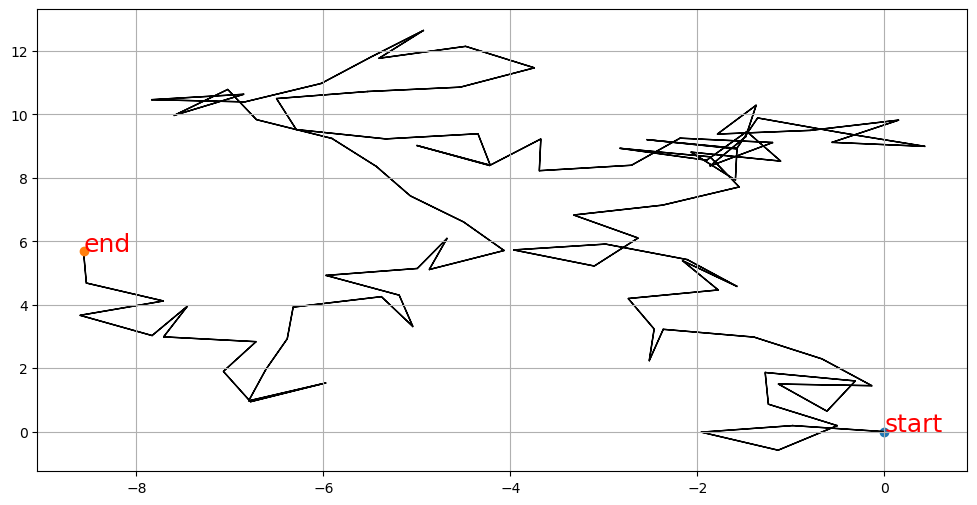

In [194]:
origin = (0,0)  
plt.figure(figsize = (12,6))
plt.grid()
plt.scatter(origin[0], origin[1])
plt.text(origin[0], origin[1], 'start', color="r", fontsize=18)

for x in range(num_steps):

    phi = np.random.uniform(0., 2. * np.pi)

    # Calculate the displacemente along the two orthogonal axes at each step.
    dx = np.cos(phi)
    dy = np.sin(phi)

    plt.arrow(origin[0], origin[1], dx, dy)
    origin =(origin[0]+dx, origin[1]+dy)

plt.scatter(origin[0], origin[1])
plt.text(origin[0], origin[1], 'end', color="r", fontsize=18)

plt.plot()

### Scaling of d

on x axi,s plot n  
on y axis, ploe mean of d  

In [195]:
d_mean = np.array([])
d_sigma = np.array([])


for n in range(0,100):  
    simulations2 = [random_walk(n) for _ in range(num_simulations)]
    x_coords2, y_coords2 = zip(*simulations2)
    distance2 = [math.sqrt(x**2+y**2) for x,y in zip(x_coords2, y_coords2)]
    d_mean = np.append(d_mean, np.mean(distance2))
    stdevm = np.std(distance2, ddof=1) / np.sqrt(len(distance2))
    d_sigma = np.append(d_sigma, stdevm)

    print(len(d_mean))

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100


In [196]:
print(d_mean)

[0.         1.         1.20474785 1.58105292 1.68107202 1.95316553
 2.2121769  2.39551584 2.5255638  2.57436157 2.79235622 2.70190531
 3.05012498 3.18345391 3.44353023 3.55405743 3.56342942 3.64276359
 3.78624056 4.12856073 4.05933406 3.71281355 4.14291224 3.98844322
 4.40630066 4.28510492 4.67135896 4.30951836 5.0305426  5.09508544
 5.23882898 4.83933977 4.99532502 4.93699857 5.25408996 5.30476278
 5.33709911 4.79786224 5.14464489 5.81106024 5.17425234 5.00224684
 5.58444826 5.97073709 5.86597806 5.83533205 5.81237779 5.76681446
 5.64860218 6.72069601 6.3504927  5.73393248 6.71270383 6.45037695
 6.12696229 6.86119993 7.24947267 6.64571194 7.30964806 6.84082698
 6.66701021 7.13013003 7.04858225 7.07691733 7.76082101 6.67185289
 6.80549837 7.44312345 6.82648905 7.33856991 7.66696858 7.17870208
 7.63042471 7.79924581 7.67099036 7.58228541 7.76115833 8.10466673
 8.26195157 8.71677773 7.93542532 8.46350742 7.90034678 8.5400987
 8.26785304 9.15743109 9.46711786 8.40803418 8.70176602 9.47233

In [197]:
x = np.linspace(0,99,100)
plt.errorplot(x, d_mean, 'r-', linewidth=2)

AttributeError: module 'matplotlib.pyplot' has no attribute 'errorplot'

In [147]:
from scipy.optimize import curve_fit

0.9703577136565016 0.04233695969168354 0.47866793262838836 0.010587055837882772


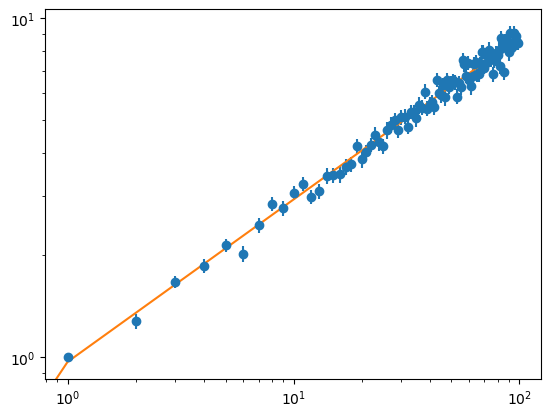

In [148]:
def power_law(x, norm, index):
    """Modello di tipo legge di potenza."""
    return norm * (x**index)

plt.figure('Grafico massa-raggio')
plt.errorbar(x, d_mean, d_sigma, fmt='o')



popt, pcov = curve_fit(power_law, x, d_mean)
norm_hat, index_hat = popt
sigma_norm, sigma_index = np.sqrt(pcov.diagonal())
print(norm_hat, sigma_norm, index_hat, sigma_index)

plt.plot(x, power_law(x, norm_hat, index_hat))
plt.xscale('log')
plt.yscale('log')

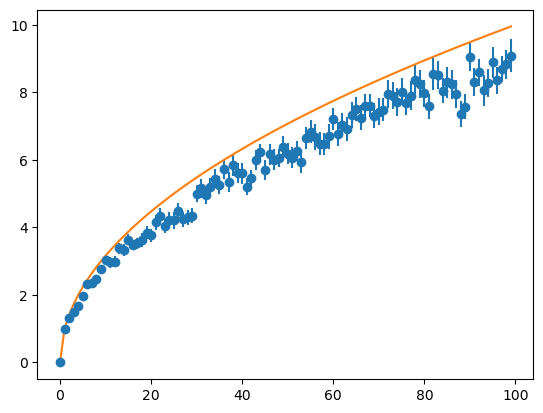

In [176]:
x = np.linspace(0,99,100)
plt.errorbar(x, d_mean, d_sigma, fmt='o')
plt.plot(x, x**(0.5))
